# IAB 網路拓撲：第一個模擬器模組

這份Notebook是人工閱讀入口。先理解資料，再依序執行生成、情境檢查及圖表。所有正式業務程式目前都在本Notebook；你明確理解並接受此版本後，才抽離成.py。

**已確認模型**：1 Donor直接連5個IAB Nodes，各1 UE。平面水平距離、靜態位置；UE只有ID與Node歸屬，不設定物理座標。每Node的三區外邊界10／30／50 m，部署區不重疊。全場配額例子近10／中13／遠7，隨機分配到Nodes且各至少2個，每區內按面積均勻生成。

**科學邊界**：這裡只驗證幾何、歸屬與重現性，不計算SNR／BER／採能。近區SNR優於遠區、自身CW自干擾完美消除保留為後續Channel假設；不把幾何圈或顏色當成品質實測。位置靜態不代表後續通道／資源不隨時間更新。

執行前選擇具備Matplotlib、IPython的Python kernel。可用的既有環境及執行命令見人工導讀文件；本機檔案匯出至`notebooks/artifacts/iab-topology/`。輸出會以目前設定更新同名示例檔。


## 1. 共用資料定義：Config／DTO

`Position2D`儲存公尺座標；`FixedNodeConfig`描述Donor／IAB站點。`TopologyConfig`是輸入，總Tag數由三區配額相加。`UERecord`與`TagRecord`是結果，`TopologySnapshot`保存整份設定及結果。

frozen dataclass與tuple讓呼叫端不能改寫真值。Config的list會轉為tuple；型別註記本身不會做輸入驗證，下一節明確檢查。`example_config()`提供可替換的工程座標，Node最短間距120 m，非真實農場校準值。


In [ ]:
from dataclasses import dataclass, asdict
from enum import Enum
import math
import random

# Tag sigal level zone
class TagZone(str, Enum):
    NEAR = 'NEAR'
    MID = 'MID'
    FAR = 'FAR'

# coordiate x,y 
@dataclass(frozen=True)
class Position2D:
    x_m: float 
    y_m: float


 # The Node postion sturct
 # lile (node_id = "node=1,
 #       Position2D (x_m=0 , y_m=0)")
@dataclass(frozen=True)
class FixedNodeConfig:
    node_id: str
    position: Position2D


@dataclass(frozen=True)
class TopologyConfig:
    donor: FixedNodeConfig
    iab_nodes: tuple[FixedNodeConfig, ...]
    zone_outer_radii_m: tuple[float, float, float] = (10.0, 30.0, 50.0) # The cycle zone
    zone_tag_counts: tuple[int, int, int] = (10, 13, 7) # The cycle zone for tag {good, midle, bad}
    min_tags_per_node: int = 2
    seed: int = 42

    def __post_init__(self):
        # 接受設定cell的list寫法，但不保留呼叫端可修改的容器。
        for name in ('iab_nodes', 'zone_outer_radii_m', 'zone_tag_counts'):
            value = getattr(self, name)
            if isinstance(value, (list, tuple)):
                object.__setattr__(self, name, tuple(value))


@dataclass(frozen=True)
class UERecord:
    ue_id: str
    parent_node_id: str


@dataclass(frozen=True)
class TagRecord:
    tag_id: str
    parent_node_id: str
    zone: TagZone
    position: Position2D


@dataclass(frozen=True)
class TopologySnapshot:
    config: TopologyConfig
    ues: tuple[UERecord, ...]
    tags: tuple[TagRecord, ...]


def example_config(seed=42):
    """工程示例；固定站點不代表真實農場或通訊覆蓋已校準。"""
    positions = ((0, 0), (120, 0), (240, 0), (60, 120), (180, 120))
    return TopologyConfig(
        donor=FixedNodeConfig('Donor-1', Position2D(120, -120)),
        iab_nodes=tuple(FixedNodeConfig(f'Node-{i}', Position2D(*xy))
                        for i, xy in enumerate(positions, 1)),
        seed=seed,
    )


## 2. 水平分區與輸入驗證

距離定義為平面歐氏距離：10 m屬近區、30 m屬中區、50 m屬遠區；各環帶排除內邊界、包含外邊界。距離0與超出最外半徑拒絕。

先閱讀分區函式，再看`validate_config`：它只讀設定，不改輸入，也不生成檔案。錯誤ID、非法數量／半徑、非有限座標、Node區域重疊／相切等都回報具體原因。負座標合法。站點ID也不能撞到將生成的UE／Tag ID。


In [2]:
def _finite_number(value):
    if isinstance(value, bool) or not isinstance(value, (int, float)):
        return False
    try:
        return math.isfinite(value)
    except OverflowError:
        return False


def _validate_radii(radii):
    if not isinstance(radii, tuple) or len(radii) != 3:
        raise ValueError('zone_outer_radii_m must contain three radii')
    if any(not _finite_number(r) or r <= 0 for r in radii):
        raise ValueError('zone_outer_radii_m must be finite and positive')
    if not radii[0] < radii[1] < radii[2]:
        raise ValueError('zone_outer_radii_m must strictly increase')


def classify_distance(distance, radii=(10.0, 30.0, 50.0)):
    """含外邊界、排除內邊界；這是部署分區，不是成功率判定。"""
    _validate_radii(radii)
    if not _finite_number(distance) or not 0 < distance <= radii[-1]:
        raise ValueError('distance must be positive and within deployment radius')
    return next(zone for zone, radius in zip(TagZone, radii) if distance <= radius)




In [3]:
def validate_config(config):
    """公開生成入口的輸入檢查；失敗不產生部分檔案或修改輸入。"""
    if not isinstance(config, TopologyConfig):
        raise ValueError('config must be TopologyConfig')
    if not isinstance(config.iab_nodes, tuple) or len(config.iab_nodes) != 5:
        raise ValueError('iab_nodes must contain exactly five nodes')
    stations = (config.donor,) + config.iab_nodes
    identifiers = []
    for station in stations:
        if not isinstance(station, FixedNodeConfig):
            raise ValueError('station must be FixedNodeConfig')
        if not isinstance(station.node_id, str) or not station.node_id.strip():
            raise ValueError('station ID must be a non-empty string')
        identifiers.append(station.node_id)
        if not isinstance(station.position, Position2D):
            raise ValueError('station position must be Position2D')
        if not all(_finite_number(v) for v in (station.position.x_m, station.position.y_m)):
            raise ValueError('station coordinates must be finite numbers')
    if len(set(identifiers)) != len(identifiers):
        raise ValueError('duplicate station ID')
    _validate_radii(config.zone_outer_radii_m)
    counts = config.zone_tag_counts
    if (not isinstance(counts, tuple) or len(counts) != 3
            or any(type(c) is not int or c < 0 for c in counts)):
        raise ValueError('zone_tag_counts must contain three non-negative integers')
    if type(config.min_tags_per_node) is not int or config.min_tags_per_node < 2:
        raise ValueError('min_tags_per_node must be an integer >= 2')
    if sum(counts) < len(config.iab_nodes) * config.min_tags_per_node:
        raise ValueError('zone_tag_counts total is below minimum required Tag count')
    if type(config.seed) is not int:
        raise ValueError('seed must be an integer')
    for identifier in identifiers:
        reserved_ue = identifier in {f'UE-{i}' for i in range(1, 6)}
        suffix = identifier.removeprefix('Tag-')
        reserved_tag = (identifier.startswith('Tag-') and suffix.isascii() and suffix.isdigit()
                        and 1 <= int(suffix) <= sum(counts)
                        and identifier == f'Tag-{int(suffix):03d}')
        if reserved_ue or reserved_tag:
            raise ValueError(f'station ID collides with generated entity ID: {identifier}')
    diameter = 2 * config.zone_outer_radii_m[-1]
    if not _finite_number(diameter):
        raise ValueError('deployment geometry cannot be represented')
    for index, left in enumerate(config.iab_nodes):
        for right in config.iab_nodes[index + 1:]:
            try:
                separation = math.hypot(left.position.x_m - right.position.x_m,
                                        left.position.y_m - right.position.y_m)
            except OverflowError as error:
                raise ValueError('node separation geometry cannot be represented') from error
            if not math.isfinite(separation):
                raise ValueError('node separation cannot be represented')
            if separation <= diameter:
                raise ValueError(f'node regions overlap or touch: {left.node_id}, {right.node_id}')


## 3. 生成入口：build_topology

輸入只需一個Config。先驗證，再使用局部RNG，避免其他模組抽亂數改變拓撲。

1. 依全場精確配額建立區域名額並打散。
2. 先隨機安排每Node最少名額，再隨機分配剩餘Tag。這不是所有合法配額配置等機率。
3. 在所屬Node對應環帶產生座標。面積均勻使用半徑平方插值，不能直接均勻抽半徑。
4. 檢查生成距離／區域；每Node建立一個邏輯UE，回傳不可變快照。

若浮點精度無法表示幾何，例如把50 m部署放到極大的座標尺度上而距離消失，明確報錯，不偷偷改Tag的區域。seed只保證同一實作／環境版本的重現，快照匯出保留完整結果。

數值端點保護：若座標轉換只造成數個浮點間距的邊界越界，將取樣半徑向環帶內側移動至多8個相關ulp，再核對實際座標仍在原區；不放寬分區或重抽。若精度不足以表示環帶則拒絕。


In [4]:
def _position_in_ring(centre, radius, angle, inner, outer):
    def point_at(r):
        return Position2D(centre.x_m + r * math.cos(angle),
                          centre.y_m + r * math.sin(angle))

    position = point_at(radius)
    distance = math.hypot(position.x_m - centre.x_m, position.y_m - centre.y_m)
    if inner < distance <= outer:
        return position
    # 只修正座標運算的端點捨入；不重抽、不放寬實際分區。
    tolerance = 8 * max(math.ulp(float(centre.x_m)), math.ulp(float(centre.y_m)), math.ulp(outer))
    near_boundary = min(abs(distance - inner), abs(distance - outer)) <= tolerance
    if tolerance < (outer - inner) / 2 and near_boundary:
        position = point_at(min(outer - tolerance, max(inner + tolerance, radius)))
        distance = math.hypot(position.x_m - centre.x_m, position.y_m - centre.y_m)
        if inner < distance <= outer:
            return position
    raise ValueError('generated geometry loses distance to float precision')


def build_topology(config):
    """由設定建立靜態快照；只使用局部亂數，不改全域RNG。"""
    validate_config(config)
    rng = random.Random(config.seed)
    zones = [zone for zone, count in zip(TagZone, config.zone_tag_counts)
             for _ in range(count)]
    rng.shuffle(zones)
    nodes = config.iab_nodes
    owners = [node for node in nodes for _ in range(config.min_tags_per_node)]
    rng.shuffle(owners)
    owners.extend(rng.choice(nodes) for _ in range(len(zones) - len(owners)))
    tags = []
    for index, (zone, node) in enumerate(zip(zones, owners), 1):
        zone_index = list(TagZone).index(zone)
        inner = 0.0 if zone_index == 0 else config.zone_outer_radii_m[zone_index - 1]
        outer = config.zone_outer_radii_m[zone_index]
        u = 1.0 - rng.random()  # (0,1]排除中心與環帶內邊界。
        radius = outer * math.sqrt((inner / outer)**2 + u * (1 - (inner / outer)**2))
        angle = rng.uniform(0.0, math.tau)
        position = _position_in_ring(node.position, radius, angle, inner, outer)
        tags.append(TagRecord(f'Tag-{index:03d}', node.node_id, zone, position))
    ues = tuple(UERecord(f'UE-{i}', node.node_id) for i, node in enumerate(nodes, 1))
    return TopologySnapshot(config, ues, tuple(tags))


## 4. 從同一快照推導表格

設定表保存seed與完整座標／配額；Node表列UE及三區數量；Tag表列ID、座標、所屬Node、水平距離及分區；Link表列5條回傳、5條UE歸屬及每Tag一條接入關係。不在快照中另外保存可能失去同步的距離或統計。


In [5]:
from collections import Counter
from pathlib import Path
import csv
import json


def topology_tables(snapshot):
    """表格只推導同一快照，不重新抽樣或保存另一套真值。"""
    config = snapshot.config
    counts = Counter((tag.parent_node_id, tag.zone) for tag in snapshot.tags)
    nodes = []
    for node, ue in zip(config.iab_nodes, snapshot.ues):
        near, mid, far = (counts[node.node_id, zone] for zone in TagZone)
        nodes.append(dict(node_id=node.node_id, x_m=node.position.x_m, y_m=node.position.y_m,
                          donor_id=config.donor.node_id, ue_id=ue.ue_id,
                          near=near, mid=mid, far=far, total=near + mid + far))
    positions = {node.node_id: node.position for node in config.iab_nodes}
    tags = []
    for tag in snapshot.tags:
        owner = positions[tag.parent_node_id]
        distance = math.hypot(tag.position.x_m - owner.x_m, tag.position.y_m - owner.y_m)
        tags.append(dict(tag_id=tag.tag_id, parent_node_id=tag.parent_node_id,
                         x_m=tag.position.x_m, y_m=tag.position.y_m,
                         distance_m=distance, zone=tag.zone.value))
    links = [dict(kind='BACKHAUL', source=config.donor.node_id, target=n.node_id)
             for n in config.iab_nodes]
    links += [dict(kind='UE_ASSOCIATION', source=u.parent_node_id, target=u.ue_id)
              for u in snapshot.ues]
    links += [dict(kind='TAG_ACCESS', source=t.parent_node_id, target=t.tag_id)
              for t in snapshot.tags]
    settings = [dict(parameter='seed', value=config.seed),
                dict(parameter='zone_outer_radii_m', value=config.zone_outer_radii_m),
                dict(parameter='zone_tag_counts', value=config.zone_tag_counts),
                dict(parameter='min_tags_per_node', value=config.min_tags_per_node),
                dict(parameter='donor', value=asdict(config.donor)),
                dict(parameter='iab_nodes', value=[asdict(n) for n in config.iab_nodes])]
    return dict(settings=settings, nodes=nodes, tags=tags, links=links)




## 5. 部署圖與匯出

圖使用等比例公尺座標，顯示Donor、五個Nodes、三區邊界及Tag。Tag顏色代表近／中／遠，數字是Tag ID尾碼。UE只在歸屬表，不畫假位置。

`export_topology`接收同一快照，保存完整JSON、四份CSV及PNG／SVG；不重新抽樣。圖中採英文ID與單位，避免既有環境缺中文字型；模型說明與導讀使用繁中。


In [6]:
def plot_topology(snapshot):
    """等比例平面部署圖；顏色只表示幾何分區，UE不畫物理位置。"""
    from matplotlib import pyplot as plt
    from matplotlib.patches import Circle
    fig, ax = plt.subplots(figsize=(11, 8), layout='constrained')
    colors = {TagZone.NEAR: '#087f8c', TagZone.MID: '#c66a10', TagZone.FAR: '#7851a9'}
    config = snapshot.config
    donor = config.donor
    for node in config.iab_nodes:
        ax.plot([donor.position.x_m, node.position.x_m],
                [donor.position.y_m, node.position.y_m], color='#87929e', lw=0.9, zorder=0)
        for zone, radius in zip(TagZone, config.zone_outer_radii_m):
            ax.add_patch(Circle((node.position.x_m, node.position.y_m), radius,
                                fill=False, color=colors[zone], linewidth=1.0, alpha=0.75))
        ax.annotate(node.node_id,
                    (node.position.x_m, node.position.y_m + config.zone_outer_radii_m[-1] + 3),
                    ha='center', va='bottom', fontsize=9, weight='bold')
    ax.scatter([n.position.x_m for n in config.iab_nodes],
               [n.position.y_m for n in config.iab_nodes], marker='s', s=65,
               color='#263544', label='IAB Node / Reader', zorder=4)
    ax.scatter([donor.position.x_m], [donor.position.y_m], marker='*', s=200,
               color='#263544', label='Donor', zorder=4)
    ax.annotate(donor.node_id, (donor.position.x_m, donor.position.y_m),
                xytext=(8, 0), textcoords='offset points', fontsize=10)
    for zone in TagZone:
        group = [t for t in snapshot.tags if t.zone == zone]
        if group:
            ax.scatter([t.position.x_m for t in group], [t.position.y_m for t in group],
                       color=colors[zone], s=28, label=f'{zone.value} Tags ({len(group)})', zorder=3)
        for tag in group:
            ax.annotate(tag.tag_id.removeprefix('Tag-'), (tag.position.x_m, tag.position.y_m),
                        xytext=(3, 3), textcoords='offset points', fontsize=6.5)
    ax.set(xlabel='x (m)', ylabel='y (m)',
           title=f'Static IAB topology | seed={config.seed} | {len(snapshot.tags)} Tags')
    ax.set_aspect('equal', adjustable='box')
    ax.grid(alpha=0.18)
    ax.margins(0.12)
    ax.legend(loc='lower left', fontsize=8)
    ax.text(0.99, 0.01, 'UEs: logical association only\nColors: distance zones, not SNR',
            transform=ax.transAxes, ha='right', va='bottom', fontsize=8)
    return fig, ax




In [7]:
def export_topology(snapshot, output_dir):
    """匯出同一快照及其圖表，供人工核對與跨版本保存。"""
    from matplotlib import pyplot as plt
    output_dir = Path(output_dir)
    output_dir.mkdir(parents=True, exist_ok=True)
    paths = {'snapshot': output_dir / 'snapshot.json'}
    payload = dict(schema_version=1, config=asdict(snapshot.config),
                   ues=[asdict(u) for u in snapshot.ues], tags=[asdict(t) for t in snapshot.tags])
    paths['snapshot'].write_text(json.dumps(payload, ensure_ascii=False, indent=2, allow_nan=False) + '\n',
                                 encoding='utf-8')
    for name, rows in topology_tables(snapshot).items():
        path = output_dir / f'{name}.csv'
        with path.open('w', newline='', encoding='utf-8') as stream:
            writer = csv.DictWriter(stream, fieldnames=list(rows[0]))
            writer.writeheader()
            writer.writerows(rows)
        paths[name] = path
    fig, _ = plot_topology(snapshot)
    try:
        for format in ('png', 'svg'):
            path = output_dir / f'deployment.{format}'
            fig.savefig(path, dpi=160)
            paths[format] = path
    finally:
        plt.close(fig)
    return paths


## 6. 可直接修改的設定與生成結果

先執行預設seed=42與配額10／13／7。可改seed觀察新的分配與座標；總配額及每Node最少2個仍須成立。若只改seed，Donor／Node固定座標不動。


In [8]:
config = example_config(seed=42)
snapshot = build_topology(config)
tables = topology_tables(snapshot)
print(f'生成完成：1 Donor、{len(config.iab_nodes)} Nodes、{len(snapshot.ues)} UE、{len(snapshot.tags)} Tags')


生成完成：1 Donor、5 Nodes、5 UE、30 Tags


In [9]:
from html import escape
from IPython.display import display, HTML, Image

for name, rows in tables.items():
    headers = list(rows[0])
    heading = {'settings': '完整設定摘要', 'nodes': 'Node數量與UE歸屬',
               'tags': 'Tag位置／距離／分區', 'links': '回傳與接入歸屬'}[name]
    content = '<h3>' + heading + '</h3><table><thead><tr>'
    content += ''.join('<th>' + escape(key) + '</th>' for key in headers)
    content += '</tr></thead><tbody>'
    for row in rows:
        content += '<tr>' + ''.join('<td>' + escape(str(row[key])) + '</td>' for key in headers) + '</tr>'
    display(HTML(content + '</tbody></table>'))


parameter,value
seed,42
zone_outer_radii_m,"(10.0, 30.0, 50.0)"
zone_tag_counts,"(10, 13, 7)"
min_tags_per_node,2
donor,"{'node_id': 'Donor-1', 'position': {'x_m': 120, 'y_m': -120}}"
iab_nodes,"[{'node_id': 'Node-1', 'position': {'x_m': 0, 'y_m': 0}}, {'node_id': 'Node-2', 'position': {'x_m': 120, 'y_m': 0}}, {'node_id': 'Node-3', 'position': {'x_m': 240, 'y_m': 0}}, {'node_id': 'Node-4', 'position': {'x_m': 60, 'y_m': 120}}, {'node_id': 'Node-5', 'position': {'x_m': 180, 'y_m': 120}}]"


node_id,x_m,y_m,donor_id,ue_id,near,mid,far,total
Node-1,0,0,Donor-1,UE-1,2,3,3,8
Node-2,120,0,Donor-1,UE-2,1,1,1,3
Node-3,240,0,Donor-1,UE-3,3,4,1,8
Node-4,60,120,Donor-1,UE-4,2,2,1,5
Node-5,180,120,Donor-1,UE-5,2,3,1,6


tag_id,parent_node_id,x_m,y_m,distance_m,zone
Tag-001,Node-5,174.1063074302299,99.91561124436129,20.931275254857027,MID
Tag-002,Node-4,64.06724480512494,149.09979403313113,29.382656331167034,MID
Tag-003,Node-3,262.67331601498324,12.426196924361742,25.855166391232387,MID
Tag-004,Node-2,157.14474611455543,27.34597626539543,46.12520549355147,FAR
Tag-005,Node-2,102.86941863752779,-19.600109685806494,26.031156668729224,MID
Tag-006,Node-1,-5.462265968595314,5.803484521502326,7.969741658485021,NEAR
Tag-007,Node-4,59.05335561742059,128.84042766701828,8.890967153400767,NEAR
Tag-008,Node-1,-7.337113069012945,-9.840889270920806,12.275028709946254,MID
Tag-009,Node-3,249.6591666179786,17.87164501976629,20.314900823445075,MID
Tag-010,Node-5,189.21220682857748,135.22608968143925,17.796026568864193,MID


kind,source,target
BACKHAUL,Donor-1,Node-1
BACKHAUL,Donor-1,Node-2
BACKHAUL,Donor-1,Node-3
BACKHAUL,Donor-1,Node-4
BACKHAUL,Donor-1,Node-5
UE_ASSOCIATION,Node-1,UE-1
UE_ASSOCIATION,Node-2,UE-2
UE_ASSOCIATION,Node-3,UE-3
UE_ASSOCIATION,Node-4,UE-4
UE_ASSOCIATION,Node-5,UE-5


## 7. Notebook情境驗收

下列示例會真的呼叫公開入口，以assert檢查模型。完整邊界案例另外位於`tests/test_topology_notebook.py`，同樣載入本Notebook的definitions cells，沒有另一套業務實作。

測試通過表示此拓撲行為成立，不代表SNR／BER／RF採能或標準符合性已驗證。


In [10]:
from dataclasses import replace, FrozenInstanceError

scenario_results = []

def passed(name):
    scenario_results.append({'情境': name, '結果': 'PASS'})

assert len(snapshot.tags) == 30 and len(snapshot.ues) == 5
assert Counter(t.zone.value for t in snapshot.tags) == {'NEAR': 10, 'MID': 13, 'FAR': 7}
assert min(Counter(t.parent_node_id for t in snapshot.tags).values()) >= 2
passed('30 Tags精確配額與每Node至少2個')
assert build_topology(config) == snapshot
assert build_topology(replace(config, seed=43)) != snapshot
passed('相同seed重現／不同seed示例有變化')
minimal = build_topology(replace(config, zone_tag_counts=(10, 0, 0)))
assert set(Counter(t.parent_node_id for t in minimal.tags).values()) == {2}
passed('10 Tags最少可行；允許空分區')
for invalid in ((9, 0, 0), (0, 0, 0)):
    try:
        build_topology(replace(config, zone_tag_counts=invalid))
    except ValueError as error:
        assert 'minimum' in str(error)
    else:
        raise AssertionError('不可行配額未拒絕')
passed('9／0 Tags明確拒絕')
assert [classify_distance(d).value for d in (10, 30, 50)] == ['NEAR', 'MID', 'FAR']
for d in (0, 50.001):
    try:
        classify_distance(d)
    except ValueError:
        pass
    else:
        raise AssertionError('非法距離未拒絕')
passed('10／30／50 m含上界，0與超界拒絕')
assert Counter(row['kind'] for row in tables['links']) == {'BACKHAUL': 5, 'UE_ASSOCIATION': 5, 'TAG_ACCESS': 30}
assert all(classify_distance(row['distance_m']) .value == row['zone'] for row in tables['tags'])
passed('歸屬表與Tag幾何一致')
state = random.getstate()
assert build_topology(config) == snapshot and state == random.getstate()
passed('生成不改全域RNG')
try:
    snapshot.config.seed = 7
except FrozenInstanceError:
    pass
else:
    raise AssertionError('快照設定可被改寫')
passed('不可變設定')
for row in scenario_results:
    print(row['結果'] + '  ' + row['情境'])
print(f'Notebook教學情境：{len(scenario_results)}項通過；完整pytest覆蓋另見執行證據。')


PASS  30 Tags精確配額與每Node至少2個
PASS  相同seed重現／不同seed示例有變化
PASS  10 Tags最少可行；允許空分區
PASS  9／0 Tags明確拒絕
PASS  10／30／50 m含上界，0與超界拒絕
PASS  歸屬表與Tag幾何一致
PASS  生成不改全域RNG
PASS  不可變設定
Notebook教學情境：8項通過；完整pytest覆蓋另見執行證據。


以下檔案皆來自本次同一快照：
snapshot → notebooks/artifacts/iab-topology/snapshot.json
settings → notebooks/artifacts/iab-topology/settings.csv
nodes → notebooks/artifacts/iab-topology/nodes.csv
tags → notebooks/artifacts/iab-topology/tags.csv
links → notebooks/artifacts/iab-topology/links.csv
png → notebooks/artifacts/iab-topology/deployment.png
svg → notebooks/artifacts/iab-topology/deployment.svg


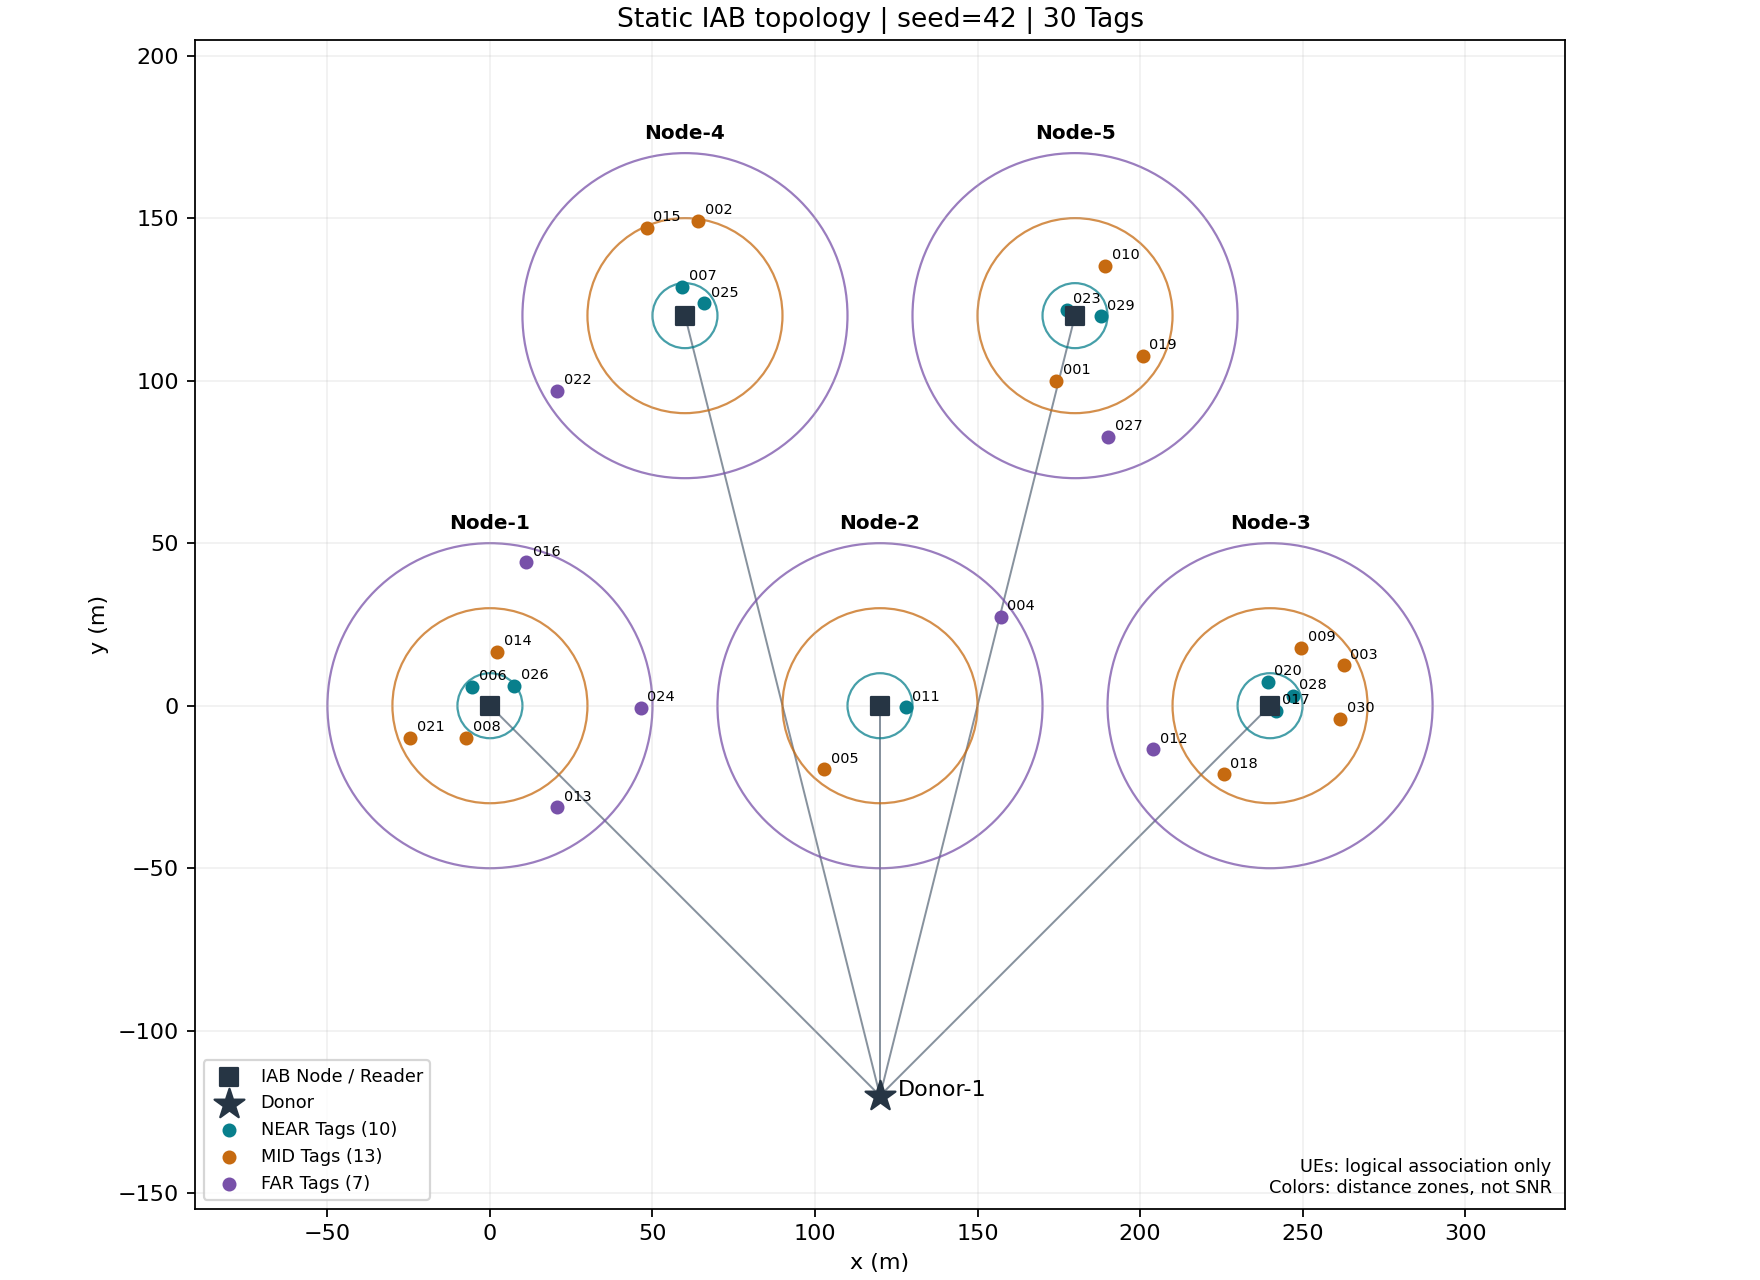

In [11]:
project_root = Path.cwd() if (Path.cwd() / 'AgentDoc').is_dir() else Path.cwd().parent
output_dir = project_root / 'notebooks' / 'artifacts' / 'iab-topology'
exported = export_topology(snapshot, output_dir)
print('以下檔案皆來自本次同一快照：')
for name, path in exported.items():
    print(name, '→', path.relative_to(project_root))
display(Image(filename=str(exported['png'])))


## 8. 人工導讀與接受

依序閱讀：資料定義→分區／驗證→歸屬配額→面積取樣→快照→情境→表與圖。建議挑一個Tag，從Tag明細找所屬Node，手算水平距離，對照分區與圖；再改seed，確認固定站點不動、配額精確保持。

你可以逐段提問或要求修正。我們會處理回饋並複驗，直到你明確表示理解並接受此版本Notebook。**目前狀態是待人工接受，不是已完成接受。** 接受後才建立共用contracts.py及實作模組，Notebook改import，再以同設定／seed和同情境驗證等價。

程式路徑、需求／測試對照及環境／執行證據見`docs/architecture/code-trace.md`及本change的validation.md。不要以圖看起來合理代替情境測試，也不要以自動測試通過代替人的理解。
